<a href="https://colab.research.google.com/github/ane-schow/oceanografia/blob/main/Simula%C3%A7%C3%A3o_Hidrol%C3%B3gica_Aprimorada_do_Lago_do_Amor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Configurando Cenário 1: Chuva Normal (Grade 20x20m)


Iniciando simulação para: Cenário 1: Chuva Normal

Shapefile já está em EPSG:31982.
Criando malha com resolução de 20m x 20m...
Criando máscara do lago...
Pontos de entrada/saída mapeados para índices da malha:
  Rio 1: (14, 14)
  Rio 2: (11, 14)
  Vertedouro: (7, 2)

Campos u, v, p, h inicializados. Altura inicial da água no lago: 2.0 m.

Parâmetros da simulação para Cenário 1: Chuva Normal:
  dt = 0.01 s, nt = 360000 (Tempo total = 3600.00 s ou 1.00 horas)
  Vazão Rio 1 (Q1): 0.0510 m^3/s (Velocidade por célula de entrada: u=0.0000, v=-0.0000 m/s)
  Vazão Rio 2 (Q2): 0.1840 m^3/s (Velocidade por célula de entrada: u=-0.0000, v=0.0001 m/s)
  Vazão de Saída Vertedouro (Q_saida): 1.132 m^3/s
  Chuva: 47.8 mm/h (0.000013 m/s)

Iniciando loop de simulação...
Passo 0/360000: Tempo=0.00 s | Vel. máx |u|=0.00000 m/s | Vel. máx |v|=0.00057 m/s | Altura mín h=2.00000 m | Altura méd h=2.00000 m
Passo 36000/360000: Tempo=360.00 s | Vel. máx 

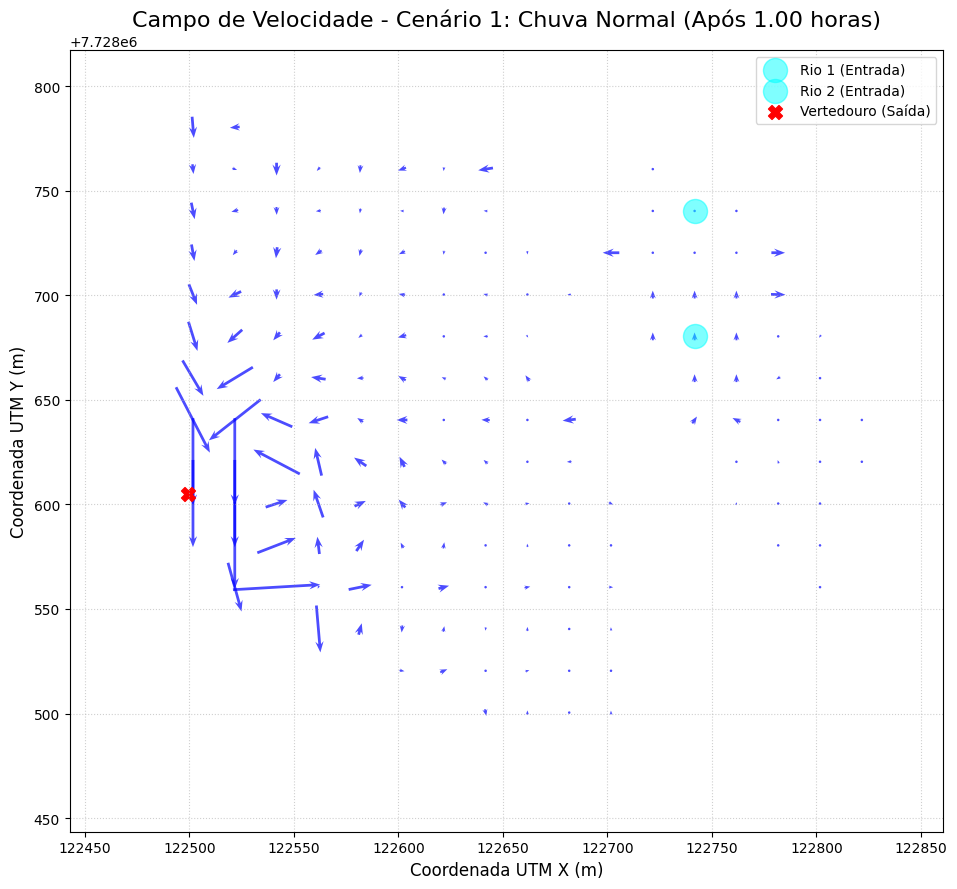

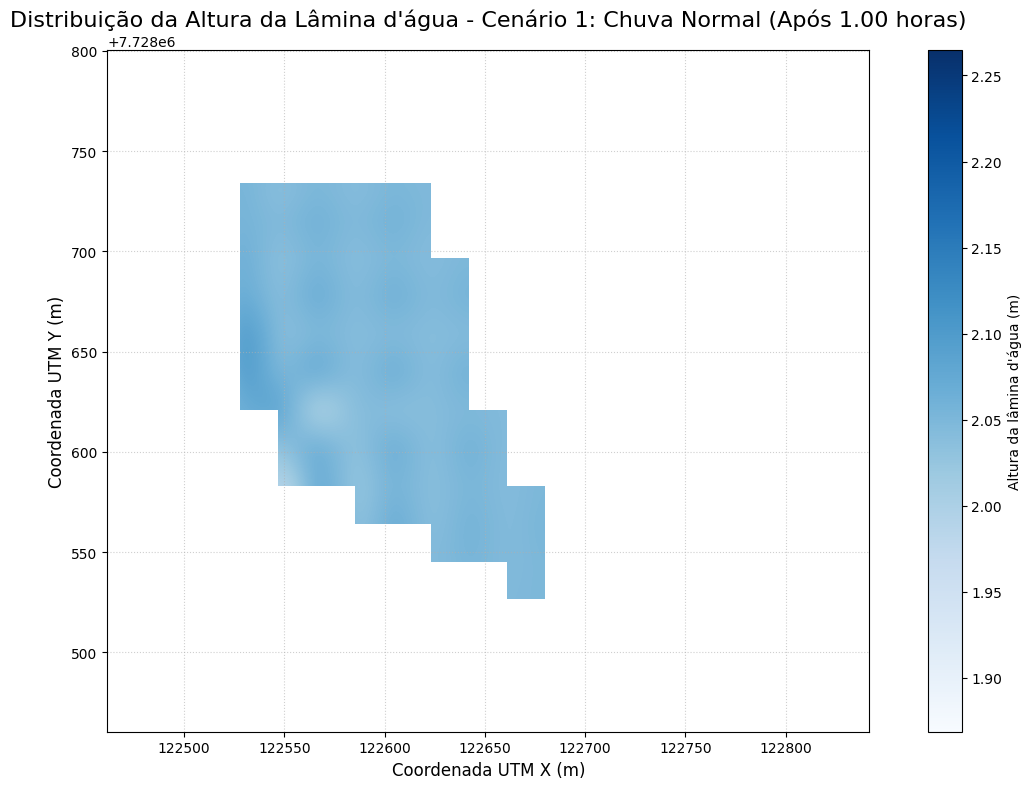


Configurando Cenário 2: Chuva Intensa (Grade 20x20m)


Iniciando simulação para: Cenário 2: Chuva Intensa

Shapefile já está em EPSG:31982.
Criando malha com resolução de 20m x 20m...
Criando máscara do lago...
Pontos de entrada/saída mapeados para índices da malha:
  Rio 1: (14, 14)
  Rio 2: (11, 14)
  Vertedouro: (7, 2)

Campos u, v, p, h inicializados. Altura inicial da água no lago: 2.0 m.

Parâmetros da simulação para Cenário 2: Chuva Intensa:
  dt = 0.01 s, nt = 3168000 (Tempo total = 31680.00 s ou 8.80 horas)
  Vazão Rio 1 (Q1): 0.0612 m^3/s (Velocidade por célula de entrada: u=0.0000, v=-0.0000 m/s)
  Vazão Rio 2 (Q2): 0.2208 m^3/s (Velocidade por célula de entrada: u=-0.0000, v=0.0001 m/s)
  Vazão de Saída Vertedouro (Q_saida): 1.132 m^3/s
  Chuva: 72.0 mm/h (0.000020 m/s)

Iniciando loop de simulação...
Passo 0/3168000: Tempo=0.00 s | Vel. máx |u|=0.00000 m/s | Vel. máx |v|=0.00057 m/s | Altura mín h=2.00000 m | Altura méd h=2.00000 m
Passo 316800/3168000: Tempo=3168.00 s | 

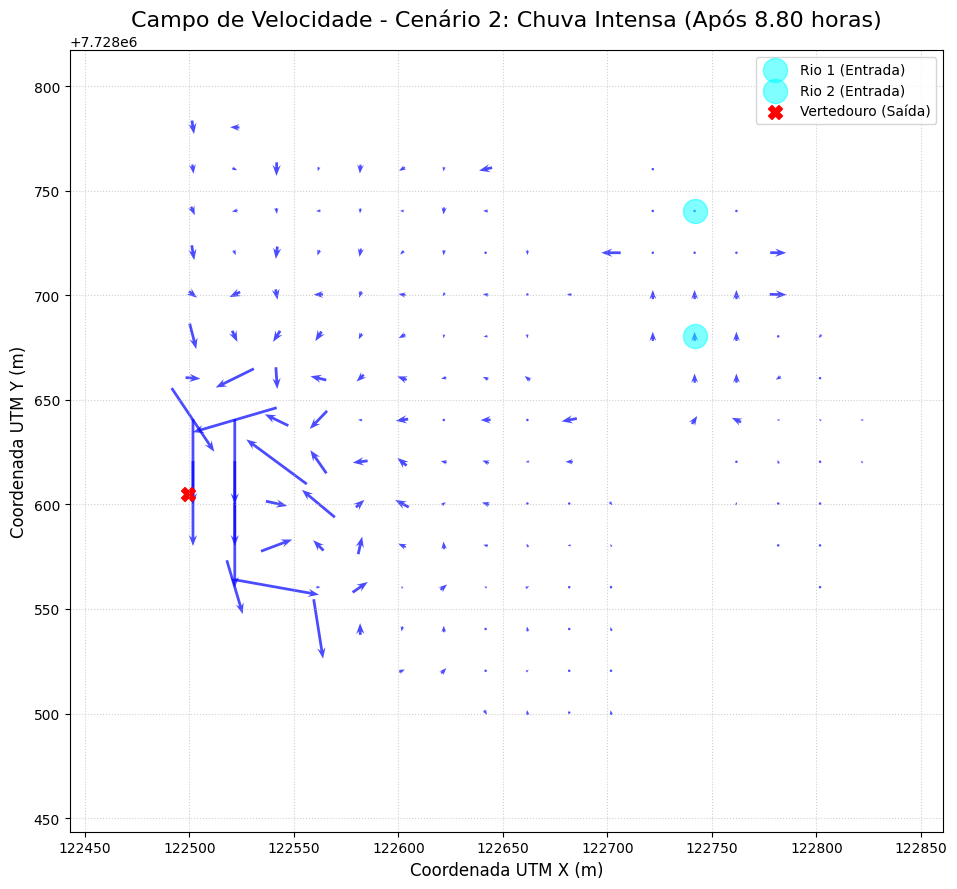

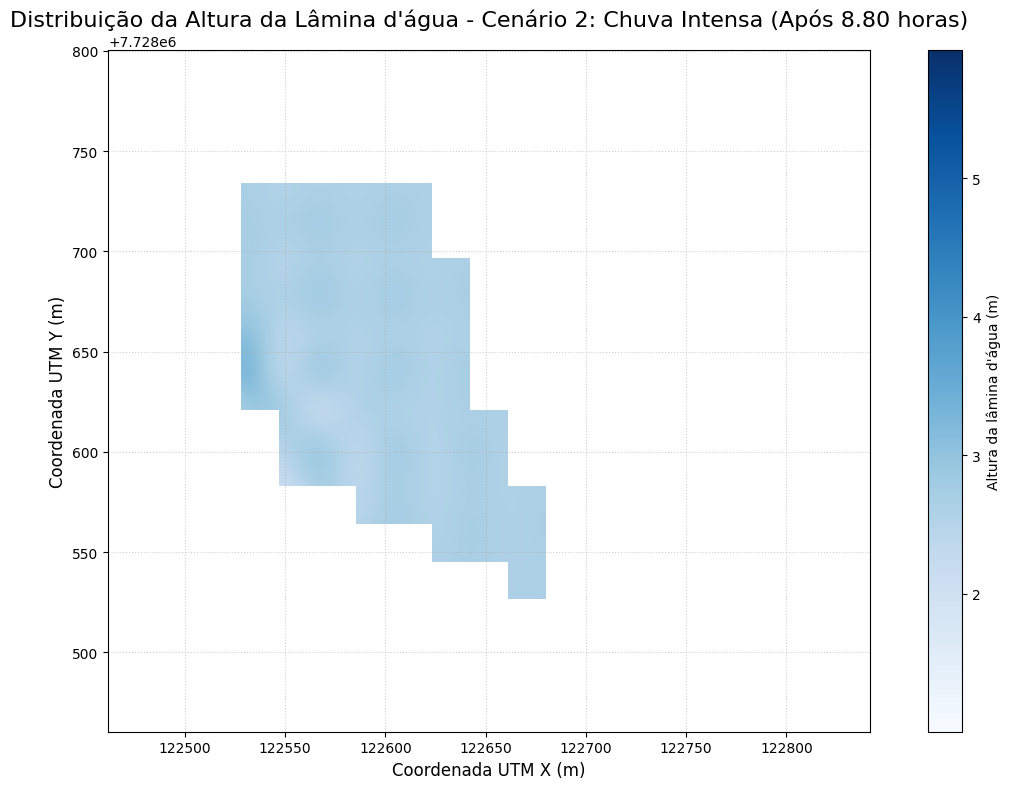

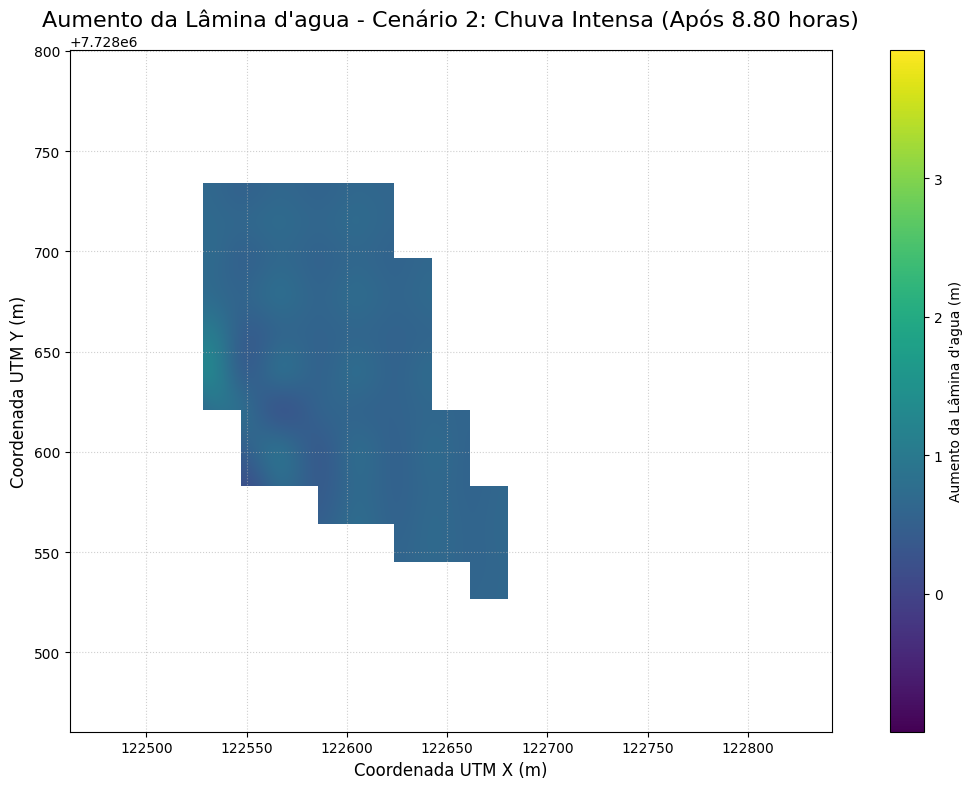

In [ ]:
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import sys
import math

# --- Constantes ---
RHO_WATER = 1000  # Densidade da água em kg/m^3
NU_WATER = 1e-6   # Viscosidade cinemática da água em m^2/s

def ponto_para_indice(pt, x_coords, y_coords, dx, dy):
    """
    Converte coordenadas geográficas (ponto Shapely) nos índices (linha, coluna)
    mais próximos na malha.
    Retorna (indice_y, indice_x) ou None se o ponto estiver muito fora da malha.
    """
    try:
        # Encontra o índice mais próximo no array de coordenadas
        ix = np.argmin(np.abs(x_coords - pt.x))
        iy = np.argmin(np.abs(y_coords - pt.y))

        # Verifica se o ponto está razoavelmente próximo do centro da célula
        # (dentro de metade do tamanho da célula)
        if np.abs(x_coords[ix] - pt.x) > dx / 2 or np.abs(y_coords[iy] - pt.y) > dy / 2:
            print(f"Aviso: Ponto {pt} está longe do centro da célula mais próxima. "
                  "Pode não corresponder exatamente ao esperado na malha.", file=sys.stderr)

        return iy, ix
    except Exception as e:
        print(f"Erro ao converter ponto {pt} para índice: {e}", file=sys.stderr)
        return None, None

def run_simulation(scenario_name, Q1_rio, Q2_rio, Q_vertedouro, chuva_mm_h, duracao_simulacao_h,
                   shapefile_path, dx, dy, h0, dt, verbose=True):
    """
    Executa a simulação do lago para um dado cenário.

    Args:
        scenario_name (str): Nome do cenário para títulos de gráficos e mensagens.
        Q1_rio (float): Vazão do Rio 1 em m^3/s.
        Q2_rio (float): Vazão do Rio 2 em m^3/s.
        Q_vertedouro (float): Vazão máxima do vertedouro em m^3/s.
        chuva_mm_h (float): Intensidade da chuva em mm/h.
        duracao_simulacao_h (float): Duração da simulação em horas.
        shapefile_path (str): Caminho para o arquivo shapefile do lago.
        dx (float): Resolução da malha em X (m).
        dy (float): Resolução da malha em Y (m).
        h0 (float): Altura inicial da lâmina d'água (m).
        dt (float): Passo de tempo da simulação (s).
        verbose (bool): Se True, imprime mensagens de progresso.
    """
    if verbose:
        print(f"\n{'='*50}")
        print(f"Iniciando simulação para: {scenario_name}")
        print(f"{'='*50}\n")

    # === 1. CARREGAR SHAPEFILE DO LAGO ===
    try:
        lago_gdf = gpd.read_file(shapefile_path)
        if lago_gdf.crs != "EPSG:31982":
            if verbose: print("Reprojetando shapefile para EPSG:31982 (UTM zone 22S, SIRGAS 2000)...")
            lago_gdf = lago_gdf.to_crs(epsg=31982)
        elif verbose:
            print("Shapefile já está em EPSG:31982.")

        if lago_gdf.empty:
            raise ValueError("O shapefile está vazio ou não contém geometrias.")

        polygon = lago_gdf.geometry.iloc[0]
        if not polygon.is_valid:
            if verbose: print("Aviso: O polígono do lago não é válido. Tentando reparar...", file=sys.stderr)
            polygon = polygon.buffer(0)

    except FileNotFoundError:
        print(f"Erro: Shapefile não encontrado em {shapefile_path}. Verifique o caminho.", file=sys.stderr)
        return
    except Exception as e:
        print(f"Erro ao carregar ou processar o shapefile: {e}", file=sys.stderr)
        return

    # === 2. CRIAR MALHA 2D ===
    if verbose: print(f"Criando malha com resolução de {dx}m x {dy}m...")
    minx, miny, maxx, maxy = polygon.bounds
    x_coords = np.arange(minx - dx, maxx + dx, dx)
    y_coords = np.arange(miny - dy, maxy + dy, dy)
    X, Y = np.meshgrid(x_coords, y_coords)
    ny, nx = len(y_coords), len(x_coords)
    A_cell = dx * dy

    # === 3. MÁSCARA DO LAGO ===
    if verbose: print("Criando máscara do lago...")
    mask = np.array([[polygon.contains(Point(xj, yi)) for xj in x_coords] for yi in y_coords])
    if not np.any(mask):
        print("Erro: Nenhuma célula da malha está dentro do polígono do lago. "
              "Verifique as coordenadas do shapefile ou o tamanho da malha (dx, dy).", file=sys.stderr)
        return

    # === 4. COORDENADAS DOS PONTOS DE ENTRADA E SAÍDA ===
    entrada_rio1 = Point(122743.93, 7728743.21)
    # COORDENADA DO RIO 2 ATUALIZADA AQUI:
    entrada_rio2 = Point(122734.23,7728673.38)
    saida_vertedouro = Point(122499.239, 7728605.238)

    iy_r1, ix_r1 = ponto_para_indice(entrada_rio1, x_coords, y_coords, dx, dy)
    iy_r2, ix_r2 = ponto_para_indice(entrada_rio2, x_coords, y_coords, dx, dy)
    iy_vt, ix_vt = ponto_para_indice(saida_vertedouro, x_coords, y_coords, dx, dy)

    if iy_r1 is None or not mask[iy_r1, ix_r1]:
        print(f"Erro: Ponto de entrada Rio 1 ({entrada_rio1}) não está dentro da máscara do lago na malha.", file=sys.stderr); return
    if iy_r2 is None or not mask[iy_r2, ix_r2]:
        print(f"Erro: Ponto de entrada Rio 2 ({entrada_rio2}) não está dentro da máscara do lago na malha.", file=sys.stderr); return
    if iy_vt is None or not mask[iy_vt, ix_vt]:
        print(f"Erro: Ponto de saída Vertedouro ({saida_vertedouro}) não está dentro da máscara do lago na malha.", file=sys.stderr); return

    if verbose:
        print(f"Pontos de entrada/saída mapeados para índices da malha:")
        print(f"  Rio 1: ({iy_r1}, {ix_r1})")
        print(f"  Rio 2: ({iy_r2}, {ix_r2})")
        print(f"  Vertedouro: ({iy_vt}, {ix_vt})\n")

    # === 5. INICIALIZAÇÃO DE CAMPOS ===
    u = np.zeros((ny, nx))
    v = np.zeros((ny, nx))
    p = np.zeros((ny, nx))
    h = np.zeros((ny, nx))
    h[mask] = h0 # Aplica a altura inicial apenas dentro da máscara do lago
    h_initial = h.copy() # Guarda a altura inicial para calcular o aumento da lâmina

    if verbose: print(f"Campos u, v, p, h inicializados. Altura inicial da água no lago: {h0} m.\n")

    # === 6. PARÂMETROS FÍSICOS E NUMÉRICOS ===
    rho = RHO_WATER
    nu = NU_WATER

    # Cálculo do número total de passos de tempo com base na duração em horas
    total_simulation_time_s = duracao_simulacao_h * 3600
    nt = int(total_simulation_time_s / dt)
    if nt == 0: nt = 1 # Garante pelo menos 1 passo para simulações muito curtas

    # Número de células para entrada de água (3x3 = 9 células)
    num_celulas_entrada = 3 * 3

    # Ângulos de entrada dos rios
    theta1 = math.radians(278.8) # Ângulo de entrada do Rio 1 em radianos (direção do fluxo)
    theta2 = math.radians(90.590) # Ângulo de entrada do Rio 2 em radianos (direção do fluxo)

    # Calcula a velocidade de entrada média para os rios
    U1_entrada_celula = Q1_rio / (num_celulas_entrada * A_cell) if num_celulas_entrada * A_cell > 0 else 0
    U2_entrada_celula = Q2_rio / (num_celulas_entrada * A_cell) if num_celulas_entrada * A_cell > 0 else 0

    u_r1 = U1_entrada_celula * np.cos(theta1)
    v_r1 = U1_entrada_celula * np.sin(theta1)
    u_r2 = U2_entrada_celula * np.cos(theta2)
    v_r2 = U2_entrada_celula * np.sin(theta2)

    # Parâmetros da chuva (convertendo mm/h para m/s)
    chuva_m_s = chuva_mm_h / 1000 / 3600

    if verbose:
        print(f"Parâmetros da simulação para {scenario_name}:")
        print(f"  dt = {dt} s, nt = {nt} (Tempo total = {total_simulation_time_s:.2f} s ou {duracao_simulacao_h:.2f} horas)")
        print(f"  Vazão Rio 1 (Q1): {Q1_rio:.4f} m^3/s (Velocidade por célula de entrada: u={u_r1:.4f}, v={v_r1:.4f} m/s)")
        print(f"  Vazão Rio 2 (Q2): {Q2_rio:.4f} m^3/s (Velocidade por célula de entrada: u={u_r2:.4f}, v={v_r2:.4f} m/s)")
        print(f"  Vazão de Saída Vertedouro (Q_saida): {Q_vertedouro} m^3/s")
        print(f"  Chuva: {chuva_mm_h} mm/h ({chuva_m_s:.6f} m/s)\n")
# === 7. LOOP DE SIMULAÇÃO ===
# Esse é o coração do modelo. Aqui, a cada passo de tempo, o código atualiza as variáveis u (velocidade horizontal),
# v (velocidade vertical), p (pressão) e h (altura da água), resolvendo as equações que representam o movimento da água no lago.
if verbose: print("Iniciando loop de simulação...")

for n in range(nt):
    # Copia os valores atuais para não sobrescrever antes das atualizações
    un, vn, pn, hn = u.copy(), v.copy(), p.copy(), h.copy()

    # --- PRESSÃO ---
    # Calcula o lado direito da equação de Poisson para a pressão (termo de divergência)
    b = np.zeros_like(p)
    b[1:-1,1:-1] = rho * (
        (un[1:-1,2:] - un[1:-1,:-2]) / (2*dx) +
        (vn[2:,1:-1] - vn[:-2,1:-1]) / (2*dy)
    ) / dt

    # Resolve a equação de Poisson iterativamente (100 vezes para garantir convergência)
    for _ in range(100):
        p[1:-1,1:-1] = (
            (pn[1:-1,2:] + pn[1:-1,:-2]) * dy**2 +
            (pn[2:,1:-1] + pn[:-2,1:-1]) * dx**2 -
            b[1:-1,1:-1] * dx**2 * dy**2
        ) / (2 * (dx**2 + dy**2))
        p[~mask] = 0  # Pressão fora do lago é zero
        pn = p.copy()

    # --- VELOCIDADES (u, v) ---
    # Calcula nova velocidade horizontal (u) com base na equação de Navier-Stokes:
    # - Termo de advecção: transporte do fluido por ele mesmo
    # - Termo de pressão: aceleração causada pela diferença de pressão
    # - Termo viscoso: difusão da velocidade (suavização)
    u[1:-1,1:-1] = (
        un[1:-1,1:-1]
        - dt * un[1:-1,1:-1] * (un[1:-1,1:-1] - un[1:-1,:-2]) / dx
        - dt * vn[1:-1,1:-1] * (un[1:-1,1:-1] - un[:-2,1:-1]) / dy
        - dt * (p[1:-1,2:] - p[1:-1,:-2]) / (2 * rho * dx)
        + nu * dt * (
            (un[1:-1,2:] - 2*un[1:-1,1:-1] + un[1:-1,:-2]) / dx**2 +
            (un[2:,1:-1] - 2*un[1:-1,1:-1] + un[:-2,1:-1]) / dy**2
        )
    )

    # Faz o mesmo para a velocidade vertical (v)
    v[1:-1,1:-1] = (
        vn[1:-1,1:-1]
        - dt * un[1:-1,1:-1] * (vn[1:-1,1:-1] - vn[1:-1,:-2]) / dx
        - dt * vn[1:-1,1:-1] * (vn[1:-1,1:-1] - vn[:-2,1:-1]) / dy
        - dt * (p[2:,1:-1] - p[:-2,1:-1]) / (2 * rho * dy)
        + nu * dt * (
            (vn[1:-1,2:] - 2*vn[1:-1,1:-1] + vn[1:-1,:-2]) / dx**2 +
            (vn[2:,1:-1] - 2*vn[1:-1,1:-1] + vn[:-2,1:-1]) / dy**2
        )
    )

    # --- CONDIÇÕES DE CONTORNO: ENTRADAS (rios) ---
    # Aplica velocidades nas regiões de entrada com um pequeno bloco 3x3 ao redor dos pontos definidos (ix_r1, iy_r1 etc.)
    for i_offset in range(-1, 2):
        for j_offset in range(-1, 2):
            current_iy_r1, current_ix_r1 = iy_r1 + i_offset, ix_r1 + j_offset
            current_iy_r2, current_ix_r2 = iy_r2 + i_offset, ix_r2 + j_offset

            if (0 <= current_iy_r1 < ny and 0 <= current_ix_r1 < nx and mask[current_iy_r1, current_ix_r1]):
                u[current_iy_r1, current_ix_r1] = u_r1
                v[current_iy_r1, current_ix_r1] = v_r1

            if (0 <= current_iy_r2 < ny and 0 <= current_ix_r2 < nx and mask[current_iy_r2, current_ix_r2]):
                u[current_iy_r2, current_ix_r2] = u_r2
                v[current_iy_r2, current_ix_r2] = v_r2

    # --- SAÍDA (vertedouro) ---
    # Calcula a área do vertedouro somando apenas as células dentro do lago e aplica uma velocidade de saída proporcional
    r_buffer = 1
    area_saida_calculada = 0
    for i in range(max(iy_vt - r_buffer, 0), min(iy_vt + r_buffer + 1, ny)):
        for j in range(max(ix_vt - r_buffer, 0), min(ix_vt + r_buffer + 1, nx)):
            if mask[i, j]:
                area_saida_calculada += A_cell

    velocidade_saida = Q_vertedouro / area_saida_calculada if area_saida_calculada > 0 else 0

    for i in range(max(iy_vt - r_buffer, 0), min(iy_vt + r_buffer + 1, ny)):
        for j in range(max(ix_vt - r_buffer, 0), min(ix_vt + r_buffer + 1, nx)):
            if mask[i, j]:
                v[i, j] = -abs(velocidade_saida)  # Saída descendente
                u[i, j] = 0

    # Zera as velocidades fora do lago
    u[~mask] = 0
    v[~mask] = 0

    # --- CONTINUIDADE: ATUALIZAÇÃO DA ALTURA DA LÂMINA D'ÁGUA ---
    # Conserva a massa de água no domínio (entrada - saída = variação de h)
    h[1:-1,1:-1] = hn[1:-1,1:-1] - dt * (
        ((hn[1:-1,1:-1] * u[1:-1,1:-1]) - (hn[1:-1,:-2] * u[1:-1,:-2])) / dx +
        ((hn[1:-1,1:-1] * v[1:-1,1:-1]) - (hn[:-2,1:-1] * v[:-2,1:-1])) / dy
    )

    # --- CHUVA ---
    # Adiciona precipitação uniformemente sobre o lago
    if chuva_m_s > 0:
        h[mask] += chuva_m_s * dt

    # Garante que h nunca fique negativo e zera fora do lago
    h[~mask] = 0
    h = np.clip(h, 0, None)

    # Imprime o progresso
    if verbose and n % (nt // 10 if nt >= 10 else 1) == 0:
        print(f"Passo {n}/{nt}: Tempo={n*dt:.2f} s | "
              f"Vel. máx |u|={np.max(np.abs(u)):.5f} m/s | "
              f"Vel. máx |v|={np.max(np.abs(v)):.5f} m/s | "
              f"Altura mín h={np.min(h[mask]):.5f} m | "
              f"Altura méd h={np.mean(h[mask]):.5f} m")

    if verbose: print(f"\nSimulação de {scenario_name} concluída.")

    # === 8. PLOTAR RESULTADOS ===
    if verbose: print("Gerando gráficos de resultados...")

    # Prepara os campos de velocidade para plotagem, definindo como NaN fora da máscara do lago
    U_plot = np.where(mask, u, np.nan)
    V_plot = np.where(mask, v, np.nan)

    # Determina uma escala para as setas do quiver com base na velocidade máxima
    max_speed = np.max(np.sqrt(np.nan_to_num(U_plot)**2 + np.nan_to_num(V_plot)**2))
    # Garante que max_speed não seja zero para evitar divisão por zero
    quiver_scale = max_speed * 10.0 if max_speed > 0 else 1.0 # Ajuste para o comprimento das setas

    # Gráfico do Campo de Velocidade
    plt.figure(figsize=(14, 9)) # Aumenta o tamanho da figura para melhor visualização
    plt.quiver(X, Y, U_plot, V_plot, scale=quiver_scale, color='blue', alpha=0.7,
               headlength=4, headaxislength=3, pivot='middle') # Ajustes visuais para setas
    # Adiciona círculos para indicar a área de entrada 3x3 e o vertedouro
    plt.scatter(x_coords[ix_r1], y_coords[iy_r1], color='cyan', s=300, marker='o', alpha=0.5, label='Rio 1 (Entrada)')
    plt.scatter(x_coords[ix_r2], y_coords[iy_r2], color='cyan', s=300, marker='o', alpha=0.5, label='Rio 2 (Entrada)')
    plt.scatter(saida_vertedouro.x, saida_vertedouro.y, color='red', s=100, marker='X', label='Vertedouro (Saída)')
    plt.title(f"Campo de Velocidade - {scenario_name} (Após {duracao_simulacao_h:.2f} horas)", fontsize=16)
    plt.xlabel("Coordenada UTM X (m)", fontsize=12)
    plt.ylabel("Coordenada UTM Y (m)", fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.gca().set_aspect('equal', adjustable='box') # Garante que os eixos tenham a mesma escala
    plt.tight_layout()
    plt.show()

    # Gráfico da Distribuição da Altura da Lâmina d'Água
    plt.figure(figsize=(12, 8))
    # Usa imshow para visualizar a altura, definindo o extent para as coordenadas corretas
    im = plt.imshow(np.where(mask, h, np.nan),
                     extent=(x_coords.min(), x_coords.max(), y_coords.min(), y_coords.max()),
                     origin='lower', cmap='Blues', interpolation='bicubic') # Usar interpolação para suavizar
    plt.colorbar(im, label='Altura da lâmina d\'água (m)')
    plt.title(f"Distribuição da Altura da Lâmina d'água - {scenario_name} (Após {duracao_simulacao_h:.2f} horas)", fontsize=16)
    plt.xlabel("Coordenada UTM X (m)", fontsize=12)
    plt.ylabel("Coordenada UTM Y (m)", fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.gca().set_aspect('equal', adjustable='box') # Garante que os eixos tenham a mesma escala
    plt.tight_layout()
    plt.show()

    # Gráfico do Aumento da Lâmina d'Água (específico para observação do cenário 2)
    if "Cenário 2" in scenario_name: # Modificado para verificar "Cenário 2" no nome
        h_increase = h - h_initial
        plt.figure(figsize=(12, 8))
        im_inc = plt.imshow(np.where(mask, h_increase, np.nan),
                             extent=(x_coords.min(), x_coords.max(), y_coords.min(), y_coords.max()),
                             origin='lower', cmap='viridis', interpolation='bicubic')
        plt.colorbar(im_inc, label='Aumento da Lâmina d\'agua (m)')
        plt.title(f"Aumento da Lâmina d'agua - {scenario_name} (Após {duracao_simulacao_h:.2f} horas)", fontsize=16)
        plt.xlabel("Coordenada UTM X (m)", fontsize=12)
        plt.ylabel("Coordenada UTM Y (m)", fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.gca().set_aspect('equal', adjustable='box')
        plt.tight_layout()
        plt.show()

# --- Configurações Comuns a Ambos os Cenários ---
shapefile_path = "/content/shape_do_lago_amor.shp" # Certifique-se de que este caminho está correto
dx = dy = 20       # RESOLUÇÃO DA MALHA EM METROS: CADA CÉLULA TERÁ 20m x 20m
h0 = 2.0           # Altura inicial uniforme da lâmina d'água em metros
dt = 0.01          # PASSO DE TEMPO DA SIMULAÇÃO EM SEGUNDOS (MANTIDO PEQUENO PARA ESTABILIDADE COM GRADE MAIOR)

# --- Cenário 1: Chuva Normal ---
# Este cenário simula as condições de chuva normal, sem aumento de vazão dos rios
# e sem precipitação adicional, para uma duração de 1 hora.
print("\n" + "="*60)
print(f"Configurando Cenário 1: Chuva Normal (Grade {dx}x{dy}m)")
print("="*60 + "\n")
Q1_rio_c1 = 0.051
Q2_rio_c1 = 0.184
Q_vertedouro_c1 = 1.132 # Vazão máxima do vertedouro
chuva_mm_h_c1 = 47.8 # Alterado de 47.0 para 47.8
duracao_simulacao_h_c1 = 1.0 # Duração da simulação para o cenário 1 (exemplo: 1 hora)

run_simulation("Cenário 1: Chuva Normal",
               Q1_rio_c1, Q2_rio_c1, Q_vertedouro_c1,
               chuva_mm_h_c1, duracao_simulacao_h_c1,
               shapefile_path, dx, dy, h0, dt)

# --- Cenário 2: Chuva Intensa ---
# Este cenário simula uma chuva de 72mm/h durante 8.8 horas, com vazões aumentadas dos rios.
# Um gráfico extra será gerado para mostrar o aumento da lâmina d'água.
print("\n" + "="*60)
print(f"Configurando Cenário 2: Chuva Intensa (Grade {dx}x{dy}m)")
print("="*60 + "\n")
Q1_rio_c2 = 0.0612 # Vazão do Rio 1 com aumento de 0.2
Q2_rio_c2 = 0.2208 # Vazão do Rio 2 com aumento de 0.2
Q_vertedouro_c2 = 1.132 # Mantém a mesma vazão máxima do vertedouro
chuva_mm_h_c2 = 72.0    # Intensidade da chuva em mm/h
duracao_simulacao_h_c2 = 8.8 # Duração da chuva e simulação em horas

run_simulation("Cenário 2: Chuva Intensa",
               Q1_rio_c2, Q2_rio_c2, Q_vertedouro_c2,
               chuva_mm_h_c2, duracao_simulacao_h_c2,
               shapefile_path, dx, dy, h0, dt)


Configurando Cenário 1: Chuva Normal


Iniciando simulação para: Cenário 1: Chuva Normal

Shapefile já está em EPSG:31982.
Criando malha com resolução de 8m x 8m...
Criando máscara do lago...
Pontos de entrada/saída mapeados para índices da malha:
  Rio 1: (34, 34)
  Rio 2: (24, 32)
  Vertedouro: (17, 3)

Campos u, v, p, h inicializados. Altura inicial da água no lago: 2.0 m.

Parâmetros da simulação para Cenário 1: Chuva Normal:
  dt = 0.05 s, nt = 72000 (Tempo total = 3600.00 s ou 1.00 horas)
  Vazão Rio 1 (Q1): 0.0510 m^3/s (Velocidade por célula de entrada: u=0.0000, v=-0.0001 m/s)
  Vazão Rio 2 (Q2): 0.1840 m^3/s (Velocidade por célula de entrada: u=-0.0000, v=0.0003 m/s)
  Vazão de Saída Vertedouro (Q_saida): 1.132 m^3/s
  Chuva: 40.0 mm/h (0.000011 m/s)

Iniciando loop de simulação...
Passo 0/72000: Tempo=0.00 s | Vel. máx |u|=0.00001 m/s | Vel. máx |v|=0.00057 m/s | Altura mín h=1.99999 m | Altura méd h=2.00000 m
Passo 7200/72000: Tempo=360.00 s | Vel. máx |u|=0.00063 m/s | Ve

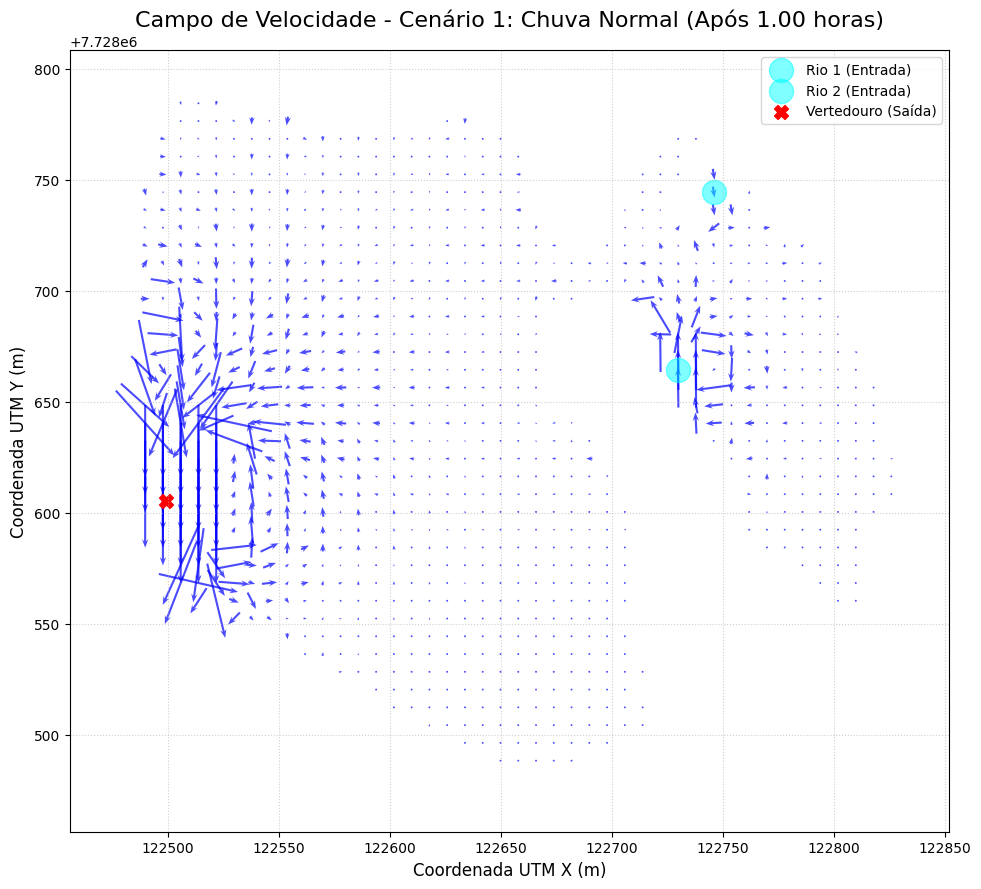

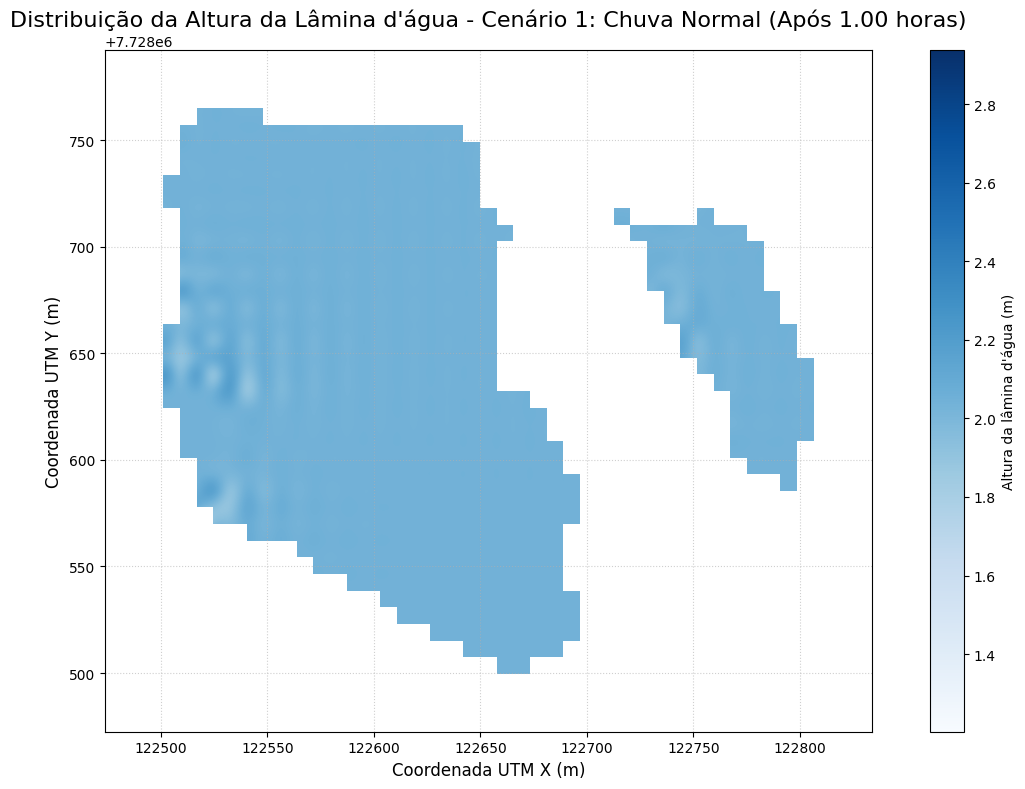


Configurando Cenário 2: Chuva Intensa


Iniciando simulação para: Cenário 2: Chuva Intensa

Shapefile já está em EPSG:31982.
Criando malha com resolução de 8m x 8m...
Criando máscara do lago...
Pontos de entrada/saída mapeados para índices da malha:
  Rio 1: (34, 34)
  Rio 2: (24, 32)
  Vertedouro: (17, 3)

Campos u, v, p, h inicializados. Altura inicial da água no lago: 2.0 m.

Parâmetros da simulação para Cenário 2: Chuva Intensa:
  dt = 0.05 s, nt = 633600 (Tempo total = 31680.00 s ou 8.80 horas)
  Vazão Rio 1 (Q1): 0.0612 m^3/s (Velocidade por célula de entrada: u=0.0000, v=-0.0001 m/s)
  Vazão Rio 2 (Q2): 0.2208 m^3/s (Velocidade por célula de entrada: u=-0.0000, v=0.0004 m/s)
  Vazão de Saída Vertedouro (Q_saida): 1.132 m^3/s
  Chuva: 72.0 mm/h (0.000020 m/s)

Iniciando loop de simulação...
Passo 0/633600: Tempo=0.00 s | Vel. máx |u|=0.00002 m/s | Vel. máx |v|=0.00057 m/s | Altura mín h=1.99999 m | Altura méd h=2.00000 m
Passo 63360/633600: Tempo=3168.00 s | Vel. máx |u|=0.00063

/tmp/ipython-input-3-2504675921.py:255: RuntimeWarning: overflow encountered in multiply
  ((hn[1:-1,1:-1] * u[1:-1,1:-1]) - (hn[1:-1,:-2] * u[1:-1,:-2])) / dx +
/tmp/ipython-input-3-2504675921.py:256: RuntimeWarning: overflow encountered in multiply
  ((hn[1:-1,1:-1] * v[1:-1,1:-1]) - (hn[:-2,1:-1] * v[:-2,1:-1])) / dy
/tmp/ipython-input-3-2504675921.py:256: RuntimeWarning: invalid value encountered in subtract
  ((hn[1:-1,1:-1] * v[1:-1,1:-1]) - (hn[:-2,1:-1] * v[:-2,1:-1])) / dy
/tmp/ipython-input-3-2504675921.py:255: RuntimeWarning: invalid value encountered in add
  ((hn[1:-1,1:-1] * u[1:-1,1:-1]) - (hn[1:-1,:-2] * u[1:-1,:-2])) / dx +
/tmp/ipython-input-3-2504675921.py:194: RuntimeWarning: overflow encountered in multiply
  - dt * un[1:-1,1:-1] * (un[1:-1,1:-1] - un[1:-1,:-2]) / dx
/tmp/ipython-input-3-2504675921.py:195: RuntimeWarning: overflow encountered in multiply
  - dt * vn[1:-1,1:-1] * (un[1:-1,1:-1] - un[:-2,1:-1]) / dy
/tmp/ipython-input-3-2504675921.py:193: RuntimeWarn

Passo 443520/633600: Tempo=22176.00 s | Vel. máx |u|=nan m/s | Vel. máx |v|=nan m/s | Altura mín h=nan m | Altura méd h=nan m
Passo 506880/633600: Tempo=25344.00 s | Vel. máx |u|=nan m/s | Vel. máx |v|=nan m/s | Altura mín h=nan m | Altura méd h=nan m
Passo 570240/633600: Tempo=28512.00 s | Vel. máx |u|=nan m/s | Vel. máx |v|=nan m/s | Altura mín h=nan m | Altura méd h=nan m

Simulação de Cenário 2: Chuva Intensa concluída.
Gerando gráficos de resultados...


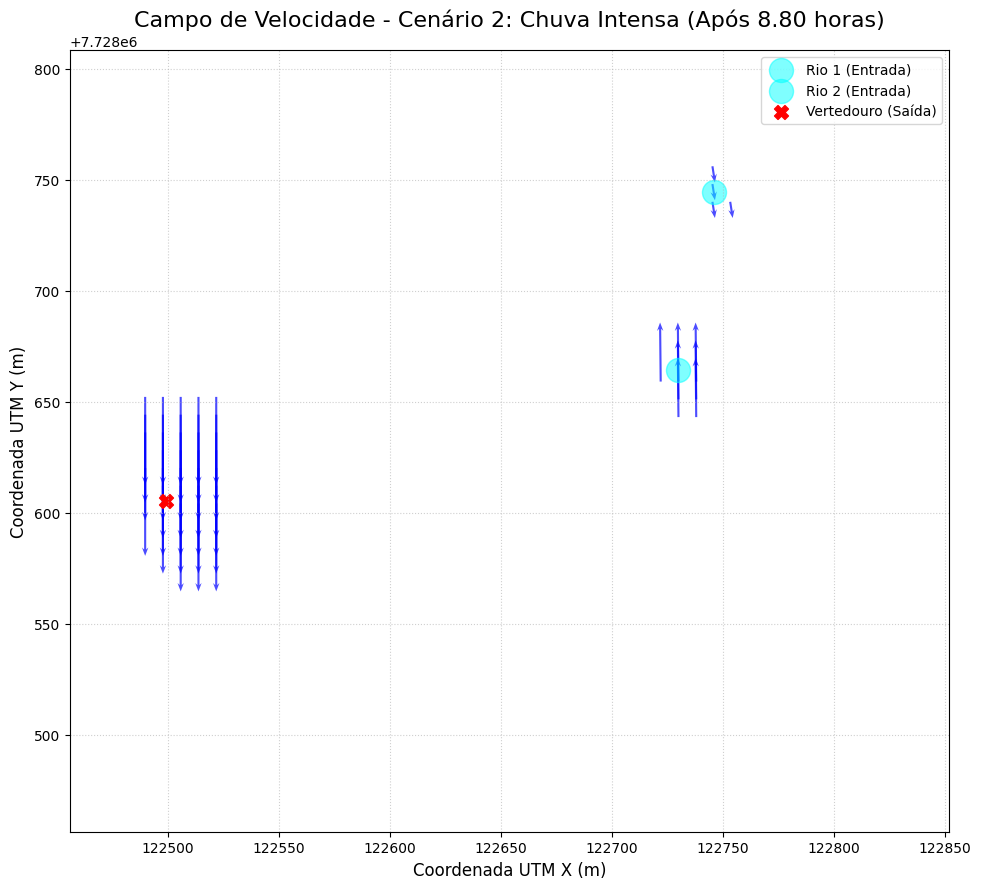

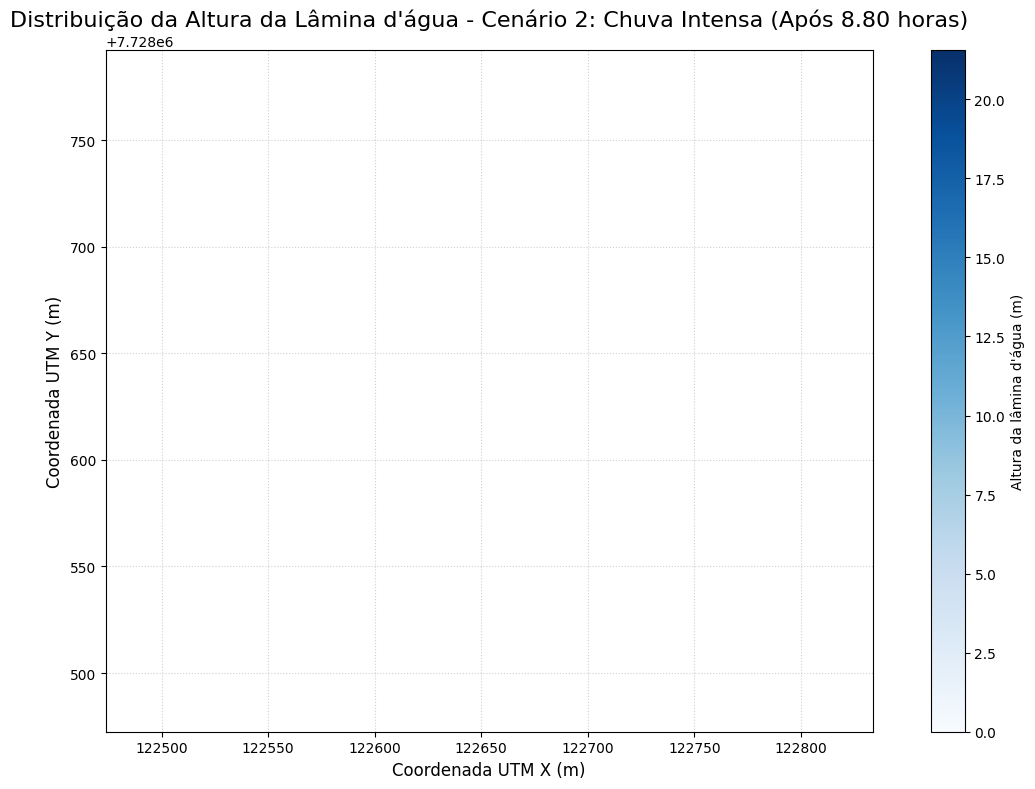

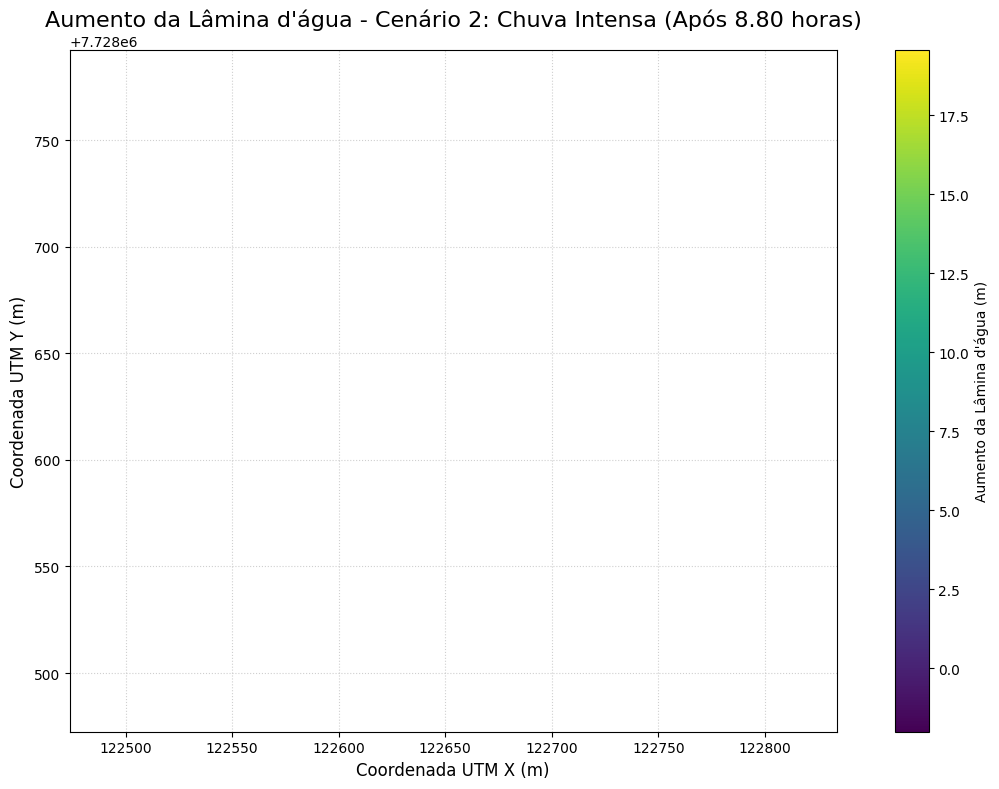

In [ ]:
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import sys
import math

# --- Constantes ---
RHO_WATER = 1000 # Densidade da água em kg/m^3
NU_WATER = 1e-6  # Viscosidade cinemática da água em m^2/s

def ponto_para_indice(pt, x_coords, y_coords, dx, dy):
    """
    Converte coordenadas geográficas (ponto Shapely) nos índices (linha, coluna)
    mais próximos na malha.
    Retorna (indice_y, indice_x) ou None se o ponto estiver muito fora da malha.
    """
    try:
        # Encontra o índice mais próximo no array de coordenadas
        ix = np.argmin(np.abs(x_coords - pt.x))
        iy = np.argmin(np.abs(y_coords - pt.y))

        # Verifica se o ponto está razoavelmente próximo do centro da célula
        # (dentro de metade do tamanho da célula)
        if np.abs(x_coords[ix] - pt.x) > dx / 2 or np.abs(y_coords[iy] - pt.y) > dy / 2:
            print(f"Aviso: Ponto {pt} está longe do centro da célula mais próxima. "
                  "Pode não corresponder exatamente ao esperado na malha.", file=sys.stderr)

        return iy, ix
    except Exception as e:
        print(f"Erro ao converter ponto {pt} para índice: {e}", file=sys.stderr)
        return None, None

def run_simulation(scenario_name, Q1_rio, Q2_rio, Q_vertedouro, chuva_mm_h, duracao_simulacao_h,
                   shapefile_path, dx, dy, h0, dt, verbose=True):
    """
    Executa a simulação do lago para um dado cenário.

    Args:
        scenario_name (str): Nome do cenário para títulos de gráficos e mensagens.
        Q1_rio (float): Vazão do Rio 1 em m^3/s.
        Q2_rio (float): Vazão do Rio 2 em m^3/s.
        Q_vertedouro (float): Vazão máxima do vertedouro em m^3/s.
        chuva_mm_h (float): Intensidade da chuva em mm/h.
        duracao_simulacao_h (float): Duração da simulação em horas.
        shapefile_path (str): Caminho para o arquivo shapefile do lago.
        dx (float): Resolução da malha em X (m).
        dy (float): Resolução da malha em Y (m).
        h0 (float): Altura inicial da lâmina d'água (m).
        dt (float): Passo de tempo da simulação (s).
        verbose (bool): Se True, imprime mensagens de progresso.
    """
    if verbose:
        print(f"\n{'='*50}")
        print(f"Iniciando simulação para: {scenario_name}")
        print(f"{'='*50}\n")

    # === 1. CARREGAR SHAPEFILE DO LAGO ===
    try:
        lago_gdf = gpd.read_file(shapefile_path)
        if lago_gdf.crs != "EPSG:31982":
            if verbose: print("Reprojetando shapefile para EPSG:31982 (UTM zone 22S, SIRGAS 2000)...")
            lago_gdf = lago_gdf.to_crs(epsg=31982)
        elif verbose:
            print("Shapefile já está em EPSG:31982.")

        if lago_gdf.empty:
            raise ValueError("O shapefile está vazio ou não contém geometrias.")

        polygon = lago_gdf.geometry.iloc[0]
        if not polygon.is_valid:
            if verbose: print("Aviso: O polígono do lago não é válido. Tentando reparar...", file=sys.stderr)
            polygon = polygon.buffer(0)

    except FileNotFoundError:
        print(f"Erro: Shapefile não encontrado em {shapefile_path}. Verifique o caminho.", file=sys.stderr)
        return
    except Exception as e:
        print(f"Erro ao carregar ou processar o shapefile: {e}", file=sys.stderr)
        return

    # === 2. CRIAR MALHA 2D ===
    if verbose: print(f"Criando malha com resolução de {dx}m x {dy}m...")
    minx, miny, maxx, maxy = polygon.bounds
    x_coords = np.arange(minx - dx, maxx + dx, dx)
    y_coords = np.arange(miny - dy, maxy + dy, dy)
    X, Y = np.meshgrid(x_coords, y_coords)
    ny, nx = len(y_coords), len(x_coords)
    A_cell = dx * dy

    # === 3. MÁSCARA DO LAGO ===
    if verbose: print("Criando máscara do lago...")
    mask = np.array([[polygon.contains(Point(xj, yi)) for xj in x_coords] for yi in y_coords])
    if not np.any(mask):
        print("Erro: Nenhuma célula da malha está dentro do polígono do lago. "
              "Verifique as coordenadas do shapefile ou o tamanho da malha (dx, dy).", file=sys.stderr)
        return

    # === 4. COORDENADAS DOS PONTOS DE ENTRADA E SAÍDA ===
    entrada_rio1 = Point(122743.93, 7728743.21)
    entrada_rio2 = Point(122727.68, 7728661.37)
    saida_vertedouro = Point(122499.239, 7728605.238)

    iy_r1, ix_r1 = ponto_para_indice(entrada_rio1, x_coords, y_coords, dx, dy)
    iy_r2, ix_r2 = ponto_para_indice(entrada_rio2, x_coords, y_coords, dx, dy)
    iy_vt, ix_vt = ponto_para_indice(saida_vertedouro, x_coords, y_coords, dx, dy)

    if iy_r1 is None or not mask[iy_r1, ix_r1]:
        print(f"Erro: Ponto de entrada Rio 1 ({entrada_rio1}) não está dentro da máscara do lago na malha.", file=sys.stderr); return
    if iy_r2 is None or not mask[iy_r2, ix_r2]:
        print(f"Erro: Ponto de entrada Rio 2 ({entrada_rio2}) não está dentro da máscara do lago na malha.", file=sys.stderr); return
    if iy_vt is None or not mask[iy_vt, ix_vt]:
        print(f"Erro: Ponto de saída Vertedouro ({saida_vertedouro}) não está dentro da máscara do lago na malha.", file=sys.stderr); return

    if verbose:
        print(f"Pontos de entrada/saída mapeados para índices da malha:")
        print(f"  Rio 1: ({iy_r1}, {ix_r1})")
        print(f"  Rio 2: ({iy_r2}, {ix_r2})")
        print(f"  Vertedouro: ({iy_vt}, {ix_vt})\n")

    # === 5. INICIALIZAÇÃO DE CAMPOS ===
    u = np.zeros((ny, nx))
    v = np.zeros((ny, nx))
    p = np.zeros((ny, nx))
    h = np.zeros((ny, nx))
    h[mask] = h0 # Aplica a altura inicial apenas dentro da máscara do lago
    h_initial = h.copy() # Guarda a altura inicial para calcular o aumento da lâmina

    if verbose: print(f"Campos u, v, p, h inicializados. Altura inicial da água no lago: {h0} m.\n")

    # === 6. PARÂMETROS FÍSICOS E NUMÉRICOS ===
    rho = RHO_WATER
    nu = NU_WATER

    # Cálculo do número total de passos de tempo com base na duração em horas
    total_simulation_time_s = duracao_simulacao_h * 3600
    nt = int(total_simulation_time_s / dt)
    if nt == 0: nt = 1 # Garante pelo menos 1 passo para simulações muito curtas

    # Número de células para entrada de água (3x3 = 9 células)
    num_celulas_entrada = 3 * 3

    # Ângulos de entrada dos rios
    theta1 = math.radians(278.8) # Ângulo de entrada do Rio 1 em radianos (direção do fluxo)
    theta2 = math.radians(90.590) # Ângulo de entrada do Rio 2 em radianos (direção do fluxo)

    # Calcula a velocidade de entrada média para os rios
    U1_entrada_celula = Q1_rio / (num_celulas_entrada * A_cell) if num_celulas_entrada * A_cell > 0 else 0
    U2_entrada_celula = Q2_rio / (num_celulas_entrada * A_cell) if num_celulas_entrada * A_cell > 0 else 0

    u_r1 = U1_entrada_celula * np.cos(theta1)
    v_r1 = U1_entrada_celula * np.sin(theta1)
    u_r2 = U2_entrada_celula * np.cos(theta2)
    v_r2 = U2_entrada_celula * np.sin(theta2)

    # Parâmetros da chuva (convertendo mm/h para m/s)
    chuva_m_s = chuva_mm_h / 1000 / 3600

    if verbose:
        print(f"Parâmetros da simulação para {scenario_name}:")
        print(f"  dt = {dt} s, nt = {nt} (Tempo total = {total_simulation_time_s:.2f} s ou {duracao_simulacao_h:.2f} horas)")
        print(f"  Vazão Rio 1 (Q1): {Q1_rio:.4f} m^3/s (Velocidade por célula de entrada: u={u_r1:.4f}, v={v_r1:.4f} m/s)")
        print(f"  Vazão Rio 2 (Q2): {Q2_rio:.4f} m^3/s (Velocidade por célula de entrada: u={u_r2:.4f}, v={v_r2:.4f} m/s)")
        print(f"  Vazão de Saída Vertedouro (Q_saida): {Q_vertedouro} m^3/s")
        print(f"  Chuva: {chuva_mm_h} mm/h ({chuva_m_s:.6f} m/s)\n")

    # === 7. LOOP DE SIMULAÇÃO ===
    if verbose: print("Iniciando loop de simulação...")
    for n in range(nt):
        un, vn, pn, hn = u.copy(), v.copy(), p.copy(), h.copy()

        # --- Pressão (método Poisson simplificado) ---
        # Resolve a equação de Poisson para a pressão, garantindo a incompressibilidade.
        b = np.zeros_like(p)
        b[1:-1,1:-1] = rho * (
            (un[1:-1,2:] - un[1:-1,:-2]) / (2*dx) +
            (vn[2:,1:-1] - vn[:-2,1:-1]) / (2*dy)
        ) / dt

        # Iterações para resolver a equação de Poisson
        for _ in range(50): # Número fixo de iterações, pode não garantir convergência total
            p[1:-1,1:-1] = (
                (pn[1:-1,2:] + pn[1:-1,:-2]) * dy**2 +
                (pn[2:,1:-1] + pn[:-2,1:-1]) * dx**2 -
                b[1:-1,1:-1] * dx**2 * dy**2
            ) / (2 * (dx**2 + dy**2))
            p[~mask] = 0 # Condição de contorno: pressão zero fora do lago
            pn = p.copy() # Atualiza pn para a próxima iteração do solver de Poisson

        # --- Atualização das velocidades u e v (Equações de Momento Simplificadas) ---
        # Termo de advecção (convecção), termo de gradiente de pressão e termo viscoso (difusão)
        u[1:-1,1:-1] = (
            un[1:-1,1:-1]
            - dt * un[1:-1,1:-1] * (un[1:-1,1:-1] - un[1:-1,:-2]) / dx
            - dt * vn[1:-1,1:-1] * (un[1:-1,1:-1] - un[:-2,1:-1]) / dy
            - dt * (p[1:-1,2:] - p[1:-1,:-2]) / (2 * rho * dx)
            + nu * dt * (
                (un[1:-1,2:] - 2*un[1:-1,1:-1] + un[1:-1,:-2]) / dx**2 +
                (un[2:,1:-1] - 2*un[1:-1,1:-1] + un[:-2,1:-1]) / dy**2
            )
        )
        v[1:-1,1:-1] = (
            vn[1:-1,1:-1]
            - dt * un[1:-1,1:-1] * (vn[1:-1,1:-1] - vn[1:-1,:-2]) / dx
            - dt * vn[1:-1,1:-1] * (vn[1:-1,1:-1] - vn[:-2,1:-1]) / dy
            - dt * (p[2:,1:-1] - p[:-2,1:-1]) / (2 * rho * dy)
            + nu * dt * (
                (vn[1:-1,2:] - 2*vn[1:-1,1:-1] + vn[1:-1,:-2]) / dx**2 +
                (vn[2:,1:-1] - 2*vn[1:-1,1:-1] + vn[:-2,1:-1]) / dy**2
            )
        )

        # --- Condições de contorno de velocidade nas entradas (ÁREA 3x3) ---
        # Aplica a velocidade de entrada para o bloco 3x3 de células em torno do ponto central.
        for i_offset in range(-1, 2):
            for j_offset in range(-1, 2):
                current_iy_r1, current_ix_r1 = iy_r1 + i_offset, ix_r1 + j_offset
                current_iy_r2, current_ix_r2 = iy_r2 + i_offset, ix_r2 + j_offset

                if (0 <= current_iy_r1 < ny and 0 <= current_ix_r1 < nx and
                    mask[current_iy_r1, current_ix_r1]):
                    u[current_iy_r1, current_ix_r1] = u_r1
                    v[current_iy_r1, current_ix_r1] = v_r1

                if (0 <= current_iy_r2 < ny and 0 <= current_ix_r2 < nx and
                    mask[current_iy_r2, current_ix_r2]):
                    u[current_iy_r2, current_ix_r2] = u_r2
                    v[current_iy_r2, current_ix_r2] = v_r2

        # --- Condição de contorno da saída (vertedouro como sumidouro) ---
        r_buffer = 3 # Raio em número de células ao redor do ponto de saída
        area_saida_calculada = 0
        # Calcula a área efetiva das células na região de saída dentro do lago.
        for i in range(max(iy_vt - r_buffer, 0), min(iy_vt + r_buffer + 1, ny)):
            for j in range(max(ix_vt - r_buffer, 0), min(ix_vt + r_buffer + 1, nx)):
                if mask[i, j]:
                    area_saida_calculada += A_cell

        velocidade_saida = Q_vertedouro / area_saida_calculada if area_saida_calculada > 0 else 0

        # Aplica a velocidade de saída nas células da região do vertedouro.
        for i in range(max(iy_vt - r_buffer, 0), min(iy_vt + r_buffer + 1, ny)):
            for j in range(max(ix_vt - r_buffer, 0), min(ix_vt + r_buffer + 1, nx)):
                if mask[i, j]:
                    v[i, j] = -abs(velocidade_saida) # Fluxo para fora do lago na direção Y
                    u[i, j] = 0 # Assume-se que o fluxo é predominantemente em Y na saída

        # Zerar velocidades fora do lago (condição de não escorregamento na fronteira da terra)
        u[~mask] = 0
        v[~mask] = 0

        # --- Atualizar altura da lâmina com equação da continuidade ---
        # Esta equação expressa a conservação de massa (água) no domínio.
        h[1:-1,1:-1] = hn[1:-1,1:-1] - dt * (
            ((hn[1:-1,1:-1] * u[1:-1,1:-1]) - (hn[1:-1,:-2] * u[1:-1,:-2])) / dx +
            ((hn[1:-1,1:-1] * v[1:-1,1:-1]) - (hn[:-2,1:-1] * v[:-2,1:-1])) / dy
        )

        # --- Adicionar chuva ---
        # A precipitação é adicionada uniformemente a cada passo de tempo sobre a superfície do lago.
        if chuva_m_s > 0: # Adiciona chuva apenas se a intensidade for maior que zero
            h[mask] += chuva_m_s * dt

        # Garantir valores físicos: altura da água não pode ser negativa e deve ser zero fora do lago
        h[~mask] = 0
        h = np.clip(h, 0, None) # Garante que a altura não seja negativa

        # Imprime o progresso da simulação
        if verbose and n % (nt // 10 if nt >= 10 else 1) == 0: # Imprime a cada 10% do total de passos
            print(f"Passo {n}/{nt}: Tempo={n*dt:.2f} s | "
                  f"Vel. máx |u|={np.max(np.abs(u)):.5f} m/s | "
                  f"Vel. máx |v|={np.max(np.abs(v)):.5f} m/s | "
                  f"Altura mín h={np.min(h[mask]):.5f} m | "
                  f"Altura méd h={np.mean(h[mask]):.5f} m")

    if verbose: print(f"\nSimulação de {scenario_name} concluída.")

    # === 8. PLOTAR RESULTADOS ===
    if verbose: print("Gerando gráficos de resultados...")

    # Prepara os campos de velocidade para plotagem, definindo como NaN fora da máscara do lago
    U_plot = np.where(mask, u, np.nan)
    V_plot = np.where(mask, v, np.nan)

    # Determina uma escala para as setas do quiver com base na velocidade máxima
    max_speed = np.max(np.sqrt(np.nan_to_num(U_plot)**2 + np.nan_to_num(V_plot)**2))
    # Garante que max_speed não seja zero para evitar divisão por zero
    quiver_scale = max_speed * 10.0 if max_speed > 0 else 1.0 # Ajuste para o comprimento das setas

    # Gráfico do Campo de Velocidade
    plt.figure(figsize=(14, 9)) # Aumenta o tamanho da figura para melhor visualização
    plt.quiver(X, Y, U_plot, V_plot, scale=quiver_scale, color='blue', alpha=0.7,
               headlength=4, headaxislength=3, pivot='middle') # Ajustes visuais para setas
    # Adiciona círculos para indicar a área de entrada 3x3 e o vertedouro
    plt.scatter(x_coords[ix_r1], y_coords[iy_r1], color='cyan', s=300, marker='o', alpha=0.5, label='Rio 1 (Entrada)')
    plt.scatter(x_coords[ix_r2], y_coords[iy_r2], color='cyan', s=300, marker='o', alpha=0.5, label='Rio 2 (Entrada)')
    plt.scatter(saida_vertedouro.x, saida_vertedouro.y, color='red', s=100, marker='X', label='Vertedouro (Saída)')
    plt.title(f"Campo de Velocidade - {scenario_name} (Após {duracao_simulacao_h:.2f} horas)", fontsize=16)
    plt.xlabel("Coordenada UTM X (m)", fontsize=12)
    plt.ylabel("Coordenada UTM Y (m)", fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.gca().set_aspect('equal', adjustable='box') # Garante que os eixos tenham a mesma escala
    plt.tight_layout()
    plt.show()

    # Gráfico da Distribuição da Altura da Lâmina d'Água
    plt.figure(figsize=(12, 8))
    # Usa imshow para visualizar a altura, definindo o extent para as coordenadas corretas
    im = plt.imshow(np.where(mask, h, np.nan),
                    extent=(x_coords.min(), x_coords.max(), y_coords.min(), y_coords.max()),
                    origin='lower', cmap='Blues', interpolation='bicubic') # Usar interpolação para suavizar
    plt.colorbar(im, label='Altura da lâmina d\'água (m)')
    plt.title(f"Distribuição da Altura da Lâmina d'água - {scenario_name} (Após {duracao_simulacao_h:.2f} horas)", fontsize=16)
    plt.xlabel("Coordenada UTM X (m)", fontsize=12)
    plt.ylabel("Coordenada UTM Y (m)", fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.gca().set_aspect('equal', adjustable='box') # Garante que os eixos tenham a mesma escala
    plt.tight_layout()
    plt.show()

    # Gráfico do Aumento da Lâmina d'Água (específico para observação do cenário 2)
    if scenario_name == "Cenário 2: Chuva Intensa":
        h_increase = h - h_initial
        plt.figure(figsize=(12, 8))
        im_inc = plt.imshow(np.where(mask, h_increase, np.nan),
                            extent=(x_coords.min(), x_coords.max(), y_coords.min(), y_coords.max()),
                            origin='lower', cmap='viridis', interpolation='bicubic')
        plt.colorbar(im_inc, label='Aumento da Lâmina d\'água (m)')
        plt.title(f"Aumento da Lâmina d'água - {scenario_name} (Após {duracao_simulacao_h:.2f} horas)", fontsize=16)
        plt.xlabel("Coordenada UTM X (m)", fontsize=12)
        plt.ylabel("Coordenada UTM Y (m)", fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.gca().set_aspect('equal', adjustable='box')
        plt.tight_layout()
        plt.show()

# --- Configurações Comuns a Ambos os Cenários ---
shapefile_path = "/content/shape_do_lago_amor.shp" # Certifique-se de que este caminho está correto
dx = dy = 8       # Resolução da malha em metros (tamanho da célula)
h0 = 2.0          # Altura inicial uniforme da lâmina d'água em metros
dt = 0.05         # Passo de tempo da simulação em segundos (Cuidado: valores maiores podem causar instabilidade!)

# --- Cenário 1: Chuva Normal ---
# Este cenário simula as condições de chuva normal, sem aumento de vazão dos rios
# e sem precipitação adicional, para uma duração de 1 hora.
print("\n" + "="*60)
print("Configurando Cenário 1: Chuva Normal")
print("="*60 + "\n")
Q1_rio_c1 = 0.051
Q2_rio_c1 = 0.184
Q_vertedouro_c1 = 1.132 # Vazão máxima do vertedouro
chuva_mm_h_c1 = 47.0
duracao_simulacao_h_c1 = 1.0 # Duração da simulação para o cenário 1 (exemplo: 1 hora)

run_simulation("Cenário 1: Chuva Normal",
               Q1_rio_c1, Q2_rio_c1, Q_vertedouro_c1,
               chuva_mm_h_c1, duracao_simulacao_h_c1,
               shapefile_path, dx, dy, h0, dt)

# --- Cenário 2: Chuva Intensa ---
# Este cenário simula uma chuva de 72mm/h durante 8.8 horas, com vazões aumentadas dos rios.
# Um gráfico extra será gerado para mostrar o aumento da lâmina d'água.
print("\n" + "="*60)
print("Configurando Cenário 2: Chuva Intensa")
print("="*60 + "\n")
Q1_rio_c2 = 0.0612 # Vazão do Rio 1 com aumento de 0.2
Q2_rio_c2 = 0.2208 # Vazão do Rio 2 com aumento de 0.2
Q_vertedouro_c2 = 1.132 # Mantém a mesma vazão máxima do vertedouro
chuva_mm_h_c2 = 72.0    # Intensidade da chuva em mm/h
duracao_simulacao_h_c2 = 8.8 # Duração da chuva e simulação em horas

run_simulation("Cenário 2: Chuva Intensa",
               Q1_rio_c2, Q2_rio_c2, Q_vertedouro_c2,
               chuva_mm_h_c2, duracao_simulacao_h_c2,
               shapefile_path, dx, dy, h0, dt)
